# Reconstrucción de TC con vista dispersa (sparse-view) como un sistema lineal subdeterminado

Este cuaderno construye un pequeño problema inverso **inspirado en la TC** utilizando NumPy y CVXPY.

- Imagen: una cuadrícula de $(10 \times 10)$ (100 valores de atenuación de **píxeles** desconocidos).
- Mediciones: 30 trayectorias de rayos X a través de la cuadrícula.
- Modelo directo: $Ax=b$, donde cada entrada de la matriz es la longitud de la trayectoria de un rayo a través de un píxel.
- Dado que $A$ tiene 30 filas y 100 columnas, el sistema está subdeterminado (bajo-determinado).
- Comparamos una solución de mínimos cuadrados de norma mínima con una reconstrucción regularizada por variación total y no negatividad.


## 1. Imports and reproducibility

In [100]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

np.random.seed(42)
np.set_printoptions(precision=3, suppress=True)

N = 10                  # 10 x 10 pixels
n_pixels = N * N
n_rays = 40


## 2. Create a simple synthetic attenuation image

The phantom contains a background, a higher-attenuation circular region, and a smaller rectangular feature. Values are arbitrary attenuation units.

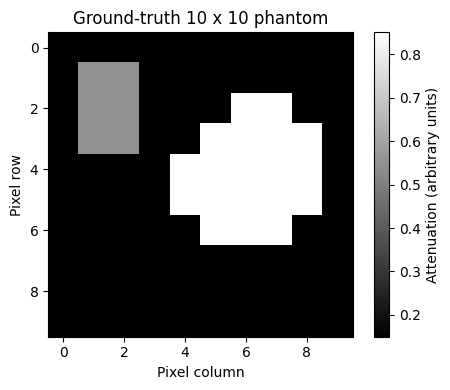

In [101]:
yy, xx = np.mgrid[0:N, 0:N]
phantom = np.full((N, N), 0.15, dtype=float)

# A disk-like feature
disk = (xx - 6.2)**2 + (yy - 4.2)**2 <= 2.5**2
phantom[disk] = 0.85

# A small rectangular feature
phantom[1:4, 1:3] = 0.55

plt.figure(figsize=(5, 4))
plt.imshow(phantom, cmap="gray", origin="upper")
plt.colorbar(label="Attenuation (arbitrary units)")
plt.title("Ground-truth 10 x 10 phantom")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.tight_layout()
plt.show()

x_true = phantom.ravel()


## 3. Construir una matriz de proyección de estilo TC

Cada medición es un rayo recto que cruza la imagen cuadrada. Para cada rayo, listamos las intersecciones con cada pixel e incluso la distancia de esta interseccion (utilizando los limites con los límites de la cuadrícula de píxeles).

Por lo tanto, $A_{ji}$ es la distancia recorrida por el rayo $j$ dentro del píxel $i$, y la medición ideal es

$$
b_j = \sum_i A_{ji}x_i.
$$

Este es un modelo simple de haz paralelo. Los sistemas de TC reales incluyen efectos físicos y de detección adicionales.

In [102]:
def ray_pixel_lengths(p0, p1, n=N):
    """Return length of the segment p0--p1 inside each n x n pixel.

    Coordinates are (x, y), with the image occupying [0,n] x [0,n].
    Pixel (row, col) occupies [col,col+1] x [row,row+1].
    """
    p0 = np.asarray(p0, dtype=float)
    p1 = np.asarray(p1, dtype=float)
    d = p1 - p0
    ray_length = np.linalg.norm(d)
    if ray_length == 0:
        raise ValueError("Ray endpoints must be distinct")

    # Parameter values where the infinite line crosses grid boundaries.
    ts = [0.0, 1.0]
    for axis in (0, 1):
        if abs(d[axis]) > 1e-12:
            for k in range(n + 1):
                t = (k - p0[axis]) / d[axis]
                if 0 < t < 1:
                    ts.append(t)

    ts = np.unique(np.clip(ts, 0, 1))
    lengths = np.zeros((n, n), dtype=float)

    for ta, tb in zip(ts[:-1], ts[1:]):
        tm = 0.5 * (ta + tb)
        midpoint = p0 + tm * d
        col = int(np.floor(midpoint[0]))
        row = int(np.floor(midpoint[1]))
        if 0 <= row < n and 0 <= col < n:
            lengths[row, col] += (tb - ta) * ray_length

    return lengths


def make_random_ray(n=N, margin=0.0):
    """Generate a random line segment whose endpoints lie on the square boundary."""
    # Choose two distinct sides, then a random point on each.
    sides = np.random.choice(4, size=2, replace=False)
    pts = []
    for side in sides:
        u = np.random.uniform(margin, n - margin)
        if side == 0:      # top
            pts.append((u, 0.0))
        elif side == 1:    # right
            pts.append((float(n), u))
        elif side == 2:    # bottom
            pts.append((u, float(n)))
        else:              # left
            pts.append((0.0, u))
    return np.array(pts[0]), np.array(pts[1])


rays = [make_random_ray() for _ in range(n_rays)]
A = np.vstack([ray_pixel_lengths(p0, p1).ravel() for p0, p1 in rays])

print("A shape:", A.shape)
print("Number of unknown pixels:", A.shape[1])
print("Number of measurements:", A.shape[0])
print("Numerical rank of A:", np.linalg.matrix_rank(A))


A shape: (40, 100)
Number of unknown pixels: 100
Number of measurements: 40
Numerical rank of A: 40


## 4. Visualize the ray paths

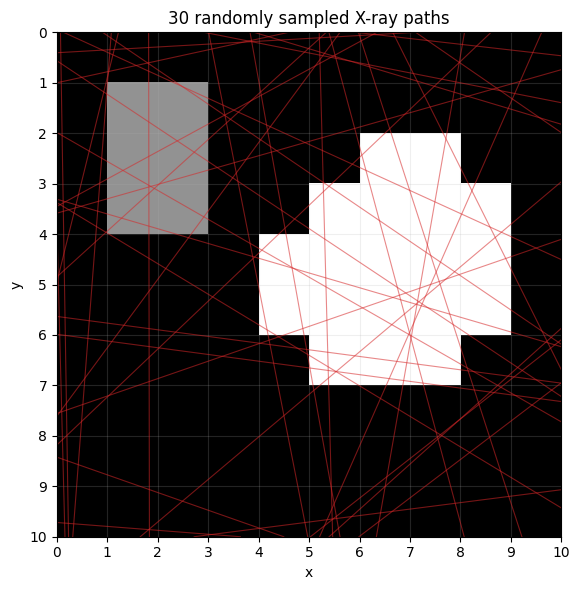

In [103]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(phantom, cmap="gray", origin="upper", extent=(0, N, N, 0))
for p0, p1 in rays:
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color="tab:red", alpha=0.55, linewidth=0.8)
ax.set_xlim(0, N)
ax.set_ylim(N, 0)
ax.set_aspect("equal")
ax.set_xticks(np.arange(0, N + 1))
ax.set_yticks(np.arange(0, N + 1))
ax.grid(alpha=0.2)
ax.set_title("30 randomly sampled X-ray paths")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.tight_layout()
plt.show()


## 5. Generate measurements and inspect the underdetermined system

We first use noiseless measurements so that the non-uniqueness is easy to see:

$$
b=Ax_{\mathrm{true}}.
$$

Because there are only 30 equations for 100 unknowns, the null space has dimension at least 70.

In [104]:
noise_std = 0.0 # dejamos el ruido de medicion en cero
b_exact = A @ x_true
b = b_exact + noise_std * np.random.randn(n_rays)

rank = np.linalg.matrix_rank(A)
nullity = n_pixels - rank

print(f"Unknowns: {n_pixels}")
print(f"Measurements: {n_rays}")
print(f"Rank(A): {rank}")
print(f"Nullity(A) = n - rank: {nullity}")
print(f"Relative residual for true image: {np.linalg.norm(A @ x_true - b) / (np.linalg.norm(b) + 1e-12):.2e}")


Unknowns: 100
Measurements: 40
Rank(A): 40
Nullity(A) = n - rank: 60
Relative residual for true image: 0.00e+00


## 6. Demostrar la multiplicidad de soluciones utilizando el espacio nulo

Si $z$ pertenece al espacio nulo de $A$, entonces $Az=0$. En consecuencia,

$$
A(x_{\mathrm{true}}+\alpha z)=Ax_{\mathrm{true}}
$$

para cualquier escalar $\alpha$. Construimos dicha dirección utilizando la descomposición en valores singulares (SVD) y mostramos que dos imágenes distintas producen exactamente las mismas mediciones.

## 7. A basic least-squares reconstruction

The minimum-norm least-squares solution is obtained with the Moore–Penrose pseudoinverse:

$$
x_{\mathrm{LS}}=A^\dagger b.
$$

It fits the measurements, but it is not guaranteed to resemble the true image. The pseudoinverse selects one particular solution, based on minimum Euclidean norm.

Measurement residual ||A x_ls - b||_2: 1.719340857072646e-14
Relative image error: 0.4604379326835776


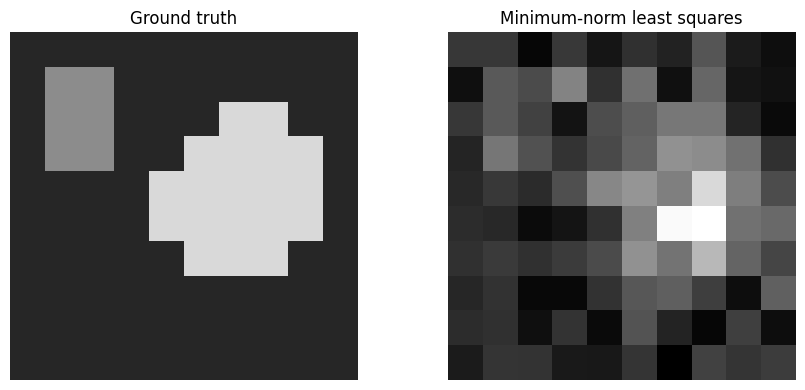

In [105]:
x_ls = np.linalg.pinv(A) @ b

print("Measurement residual ||A x_ls - b||_2:",
      np.linalg.norm(A @ x_ls - b))
print("Relative image error:",
      np.linalg.norm(x_ls - x_true) / np.linalg.norm(x_true))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(x_true.reshape(N, N), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground truth")
axes[1].imshow(x_ls.reshape(N, N), cmap="gray")
axes[1].set_title("Minimum-norm least squares")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Reconstrucción con CVXPY: no negatividad y variación total

Los coeficientes de atenuación no pueden ser negativos. También esperamos que los píxeles vecinos sean similares en muchas regiones. Codificamos estas suposiciones resolviendo:

$$
\min_x \frac12\|Ax-b\|_2^2+\lambda\,\mathrm{TV}(x)
\quad\text{sujeto a }x\geq 0.
$$

Aquí, la variación total (TV) de una imagen bidimensional $X$ de tamaño $N \times N$ (donde $x = \mathrm{vec}(X)$) se define de forma anisotrópica como la suma de las diferencias absolutas horizontales y verticales de los píxeles vecinos:

$$
\mathrm{TV}(X) = \sum_{i=1}^{N-1} \sum_{j=1}^{N} |X_{i+1, j} - X_{i, j}| + \sum_{i=1}^{N} \sum_{j=1}^{N-1} |X_{i, j+1} - X_{i, j}|
$$

Este es un problema de optimización convexo.

El parámetro de regularización $\lambda$ controla el balance:
- $\lambda$ más pequeño: prioriza el ajuste de las mediciones.
- $\lambda$ más grande: favorece imágenes más suaves y constantes a trozos (piecewise-constant).

In [106]:
lam = 0.08

X = cp.Variable((N, N))
data_fit = 0.5 * cp.sum_squares(A @ cp.vec(X, order="C") - b)
tv_penalty = (
    cp.norm1(X[1:, :] - X[:-1, :]) +
    cp.norm1(X[:, 1:] - X[:, :-1])
)

problem = cp.Problem(
    cp.Minimize(data_fit + lam * tv_penalty),
    [X >= 0]
)

installed = cp.installed_solvers()
solver = "CLARABEL" if "CLARABEL" in installed else ("SCS" if "SCS" in installed else None)
if solver is None:
    raise RuntimeError("Install a CVXPY solver, for example CLARABEL or SCS.")

problem.solve(solver=solver, verbose=False)
print("Solver:", solver)
print("Status:", problem.status)
print("Objective value:", problem.value)

x_tv = np.asarray(X.value).ravel()
print("Measurement residual ||A x_tv - b||_2:",
      np.linalg.norm(A @ x_tv - b))
print("Relative image error:",
      np.linalg.norm(x_tv - x_true) / np.linalg.norm(x_true))


Solver: CLARABEL
Status: optimal
Objective value: 1.3170402441823081
Measurement residual ||A x_tv - b||_2: 0.36146493172536387
Relative image error: 0.30278228420918857


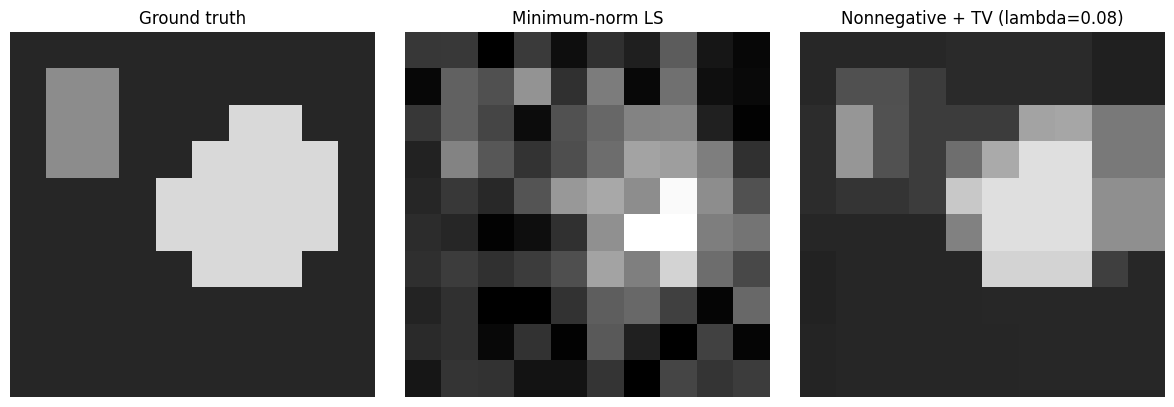

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(
    axes,
    [x_true.reshape(N, N), x_ls.reshape(N, N), x_tv.reshape(N, N)],
    ["Ground truth", "Minimum-norm LS", f"Nonnegative + TV (lambda={lam})"]
):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 9. Explore the regularization parameter

There is no universally correct value of $\lambda$. The next cell solves the same problem for several values and compares measurement fit with reconstruction error.

For real inverse problems, the true image is unknown, so the image error cannot be used directly to tune $\lambda$. One instead uses validation measurements, discrepancy principles, cross-validation, or domain knowledge.

    lambda     measurement residual   relative image error
     1e-14                  0.00000                0.30203
     5e-12                  0.00000                0.21125
    0.0001                  0.00110                0.00364
    0.0005                  0.00552                0.01821
     0.001                  0.01105                0.03641
      0.01                  0.08039                0.22252


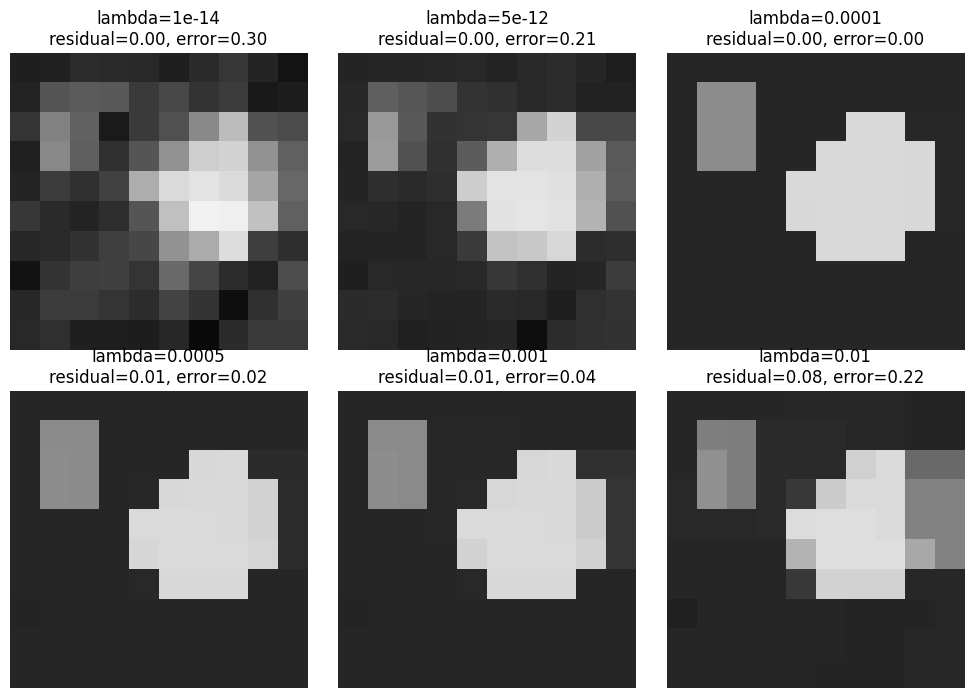

In [115]:
lambda_values = [1e-14, 5e-12, 1e-4, 0.0005, 0.001, 0.01]
results = []

for lam_i in lambda_values:
    Xi = cp.Variable((N, N))
    fit_i = 0.5 * cp.sum_squares(A @ cp.vec(Xi, order="C") - b)
    tv_i = cp.norm1(Xi[1:, :] - Xi[:-1, :]) + cp.norm1(Xi[:, 1:] - Xi[:, :-1])
    prob_i = cp.Problem(cp.Minimize(fit_i + lam_i * tv_i), [Xi >= 0])
    prob_i.solve(solver=solver, verbose=False)

    xi = np.asarray(Xi.value).ravel()
    results.append((lam_i, np.linalg.norm(A @ xi - b),
                    np.linalg.norm(xi - x_true) / np.linalg.norm(x_true), xi))

print(f"{'lambda':>10} {'measurement residual':>24} {'relative image error':>22}")
for lam_i, residual, error, _ in results:
    print(f"{lam_i:10.3g} {residual:24.5f} {error:22.5f}")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (lam_i, residual, error, xi) in zip(axes.ravel(), results):
    ax.imshow(xi.reshape(N, N), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"lambda={lam_i:g}\nresidual={residual:.2f}, error={error:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


Rank(A) SVD: 40
||A z||_2: 7.385554640068177e-16
||A x_true - A x_alternative||_2: 2.4399661153568964e-15


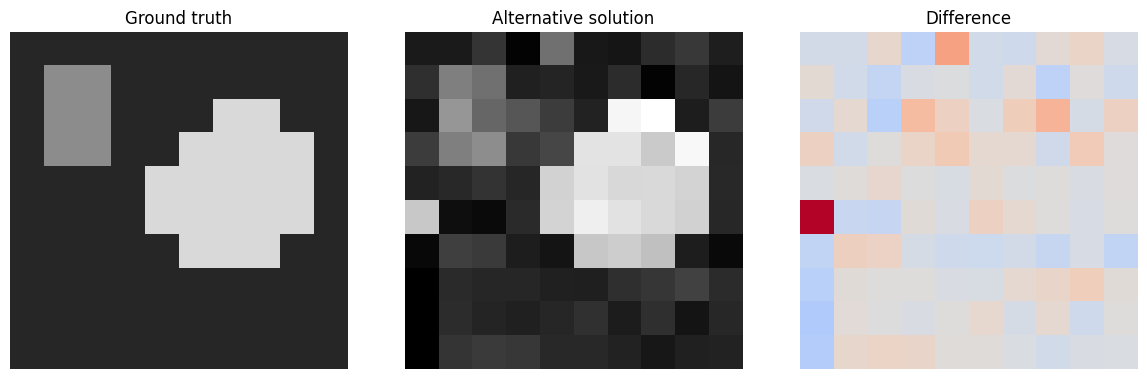

In [109]:
U, singular_values, Vt = np.linalg.svd(A, full_matrices=True)
rank_svd = np.linalg.matrix_rank(A)
print("Rank(A) SVD:", rank_svd)
z = Vt[rank_svd+10, :]             # a right-singular vector in the null space
#z = z / np.max(np.abs(z))

alpha = 1.0
x_alternative = x_true + alpha * z

print("||A z||_2:", np.linalg.norm(A @ z))
print("||A x_true - A x_alternative||_2:",
      np.linalg.norm(A @ x_true - A @ x_alternative))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
images = [
    (x_true.reshape(N, N), "Ground truth"),
    (x_alternative.reshape(N, N), "Alternative solution"),
    ((x_alternative - x_true).reshape(N, N), "Difference")
]
for ax, (im, title) in zip(axes, images):
    vmax = None if title == "Difference" else 1.0
    vmin = -np.max(np.abs(im)) if title == "Difference" else 0.0
    ax.imshow(im, cmap="coolwarm" if title == "Difference" else "gray",
              vmin=vmin, vmax=(np.max(np.abs(im)) if title == "Difference" else vmax))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
